# P04 — 4번 헤드 인젝션 OUT 니플 교체 (2026-10-29 19:40)

정리본: [`cases/P04.md`](cases/P04.md). 원시 데이터는 `cache/raw/pump/` 일별 CSV, CSV에 없는 태그만 DB(하루 캐시). 공용 함수 [`hd4_common.py`](hd4_common.py).

일지에 POL·ISO 어느 쪽 니플인지 없다. 이 노트북은 (1) 작업 전후로 어느 쪽 저항이 움직였는지,
(2) 그때 떠 있던 HD4 "헤드 토출 저항 증가" 경고가 무엇을 보고 있었는지 — **일지에 없는 저항 계단 두 개(I7 10-23 ↑, P7 10-28 ↓)** — 를 본다.

| 단계 | 내용 |
|---|---|
| 1 | 일지 |
| 2 | 그때 경고 이력 (P7·I7) |
| 3 | 작업 구간 원시 신호 — 사출 중단·순환 유지 |
| 4 | 작업 전후 저항 — 어느 쪽 니플이었나 |
| 5 | 일지에 없는 저항 계단 두 개 |
| 6 | 재생 — 일별 피처 추세, 그때 모델 상태 |

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from review_lib import paths, plot          # plot: 한글 글꼴 설정
import hd4_common as h
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 80)
FIGS = paths.CHECK_DIRS["pump"] / "figs"; FIGS.mkdir(exist_ok=True)
INC = pd.read_csv("labels_incidents.csv")
INC = INC[INC.incident_id.isin(["P02", "P03", "P04"])]
EV = h.EVENTS["P04 OUT 니플"]

## 1. 일지

In [2]:
h.actions("P04")[["작업ID", "journal", "start_dt", "end_dt", "설비상세", "조치", "부품태그", "map_note"]]

,작업ID,journal,start_dt,end_dt,설비상세,조치,부품태그,map_note
5,M-02-05-2,기계실,2026-10-29 19:40:00,2026-10-29 20:10:00,발포 2라인 4번 헤드 인젝션 OUT 니플 교체,니플 교체,피팅·니플;노즐;믹싱헤드,4번 헤드 인젝션 OUT 니플 교체. POL·ISO 어느 쪽 니플인지 미기재


## 2. 그때 경고 이력 (P7·I7)

In [3]:
ep = h.episodes()
ep[(ep.onset < "2026-10-31") & (ep.last_detected > "2026-10-22")][["episode_id", "key", "onset", "last_detected", "cleared", "reasons", "message_first", "top_features"]]

,episode_id,key,onset,last_detected,cleared,reasons,message_first,top_features
2,W0003,I7,2026-10-15 18:59:26.015,2026-10-25 08:50:00.624,NaT,pump_line_resistance_low;pump_head_resistance_high;pump_line_resistance_high,토출 배관 저항 감소 · 같은 유량 대비 압력 하강 (노즐 열림·누설 의심),r_phys;P0;decel_half_sec;release_half_sec;t_self
11,W0012,P7,2026-10-17 06:57:02.215,2026-10-24 22:37:51.791,2026-10-25 08:50:00.623,pump_line_resistance_high;pump_head_resistance_high,토출 배관·노즐 저항 증가 · 같은 유량 대비 압력 상승,r_phys;pt_std;P0;t_self;decel_half_sec
65,W0066,P7,2026-10-26 07:00:57.847,2026-10-28 09:17:57.259,2026-10-28 13:30:00.125,pump_head_resistance_high,헤드 토출 저항 증가 · POL·ISO 동시 압력 상승 (노즐·믹싱헤드 점검) — 헤드 HD4-1 P7·I7,r_phys;P0;pt_std;t_self;decel_half_sec
66,W0067,I7,2026-10-26 07:00:57.847,2026-11-06 13:45:55.878,NaT,pump_head_resistance_high;pump_line_resistance_high,헤드 토출 저항 증가 · POL·ISO 동시 압력 상승 (노즐·믹싱헤드 점검) — 헤드 HD4-1 P7·I7,r_phys;P0;t_self;pt_std;release_half_sec
126,W0127,P7,2026-10-29 08:36:38.255,2026-10-29 12:11:57.717,2026-10-29 15:30:00.041,pump_pattern,펌프 운전 패턴 변화 · 여러 지표의 관계가 평소와 다름,pt_std;r_phys;t_self;decel_half_sec;release_half_sec
149,W0150,P7,2026-10-30 16:04:42.523,2026-10-30 16:56:01.832,2026-10-30 19:30:00.313,pump_pattern,펌프 운전 패턴 변화 · 여러 지표의 관계가 평소와 다름,r_phys;P0;pt_std;t_self;release_half_sec


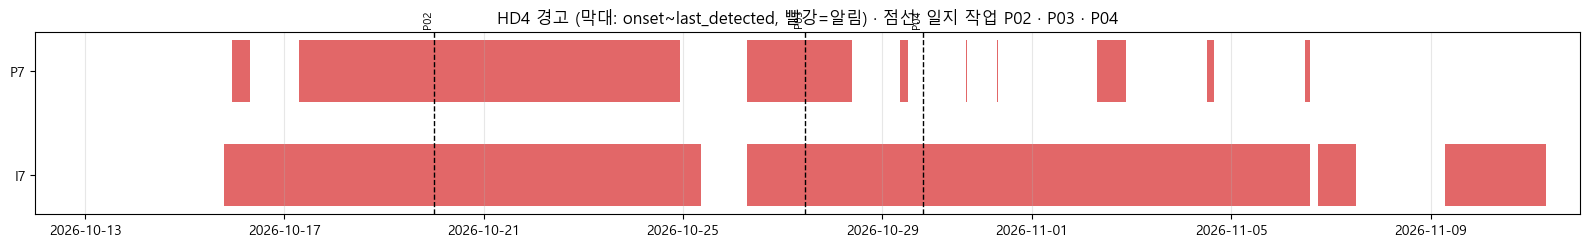

In [4]:
fig, ax = plt.subplots(figsize=(16, 2.6))
plot.timeline(h.episodes(), INC, start=pd.Timestamp("2026-10-12"), end=pd.Timestamp("2026-11-12"), ax=ax)
ax.set_title("HD4 경고 (막대: onset~last_detected, 빨강=알림) · 점선: 일지 작업 P02 · P03 · P04")
fig.tight_layout(); fig.savefig(FIGS / "HD4_timeline.png", dpi=110, bbox_inches="tight")

## 3. 작업 구간 원시 신호

In [5]:
# 원시 데이터 — cache/raw/pump 일별 CSV + HD4 릴레이(DB, 하루 캐시). 10-06 ~ 11-12 전체 약 30초
R = h.raw()
R[["FT_P7", "PT_P7", "Hz_P7", "BU_P7", "FT_I7", "PT_I7", "Hz_I7", "BU_I7", "Pump_Run_P7", "FWD_P7", "INJ_SOL_HD4"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
FT_P7,6339884.0,1426.8,1155.5,0.0,0.0,1811.0,2614.0,9978.0
PT_P7,6210010.0,76.5,57.5,0.0,3.0,97.0,128.0,187.0
Hz_P7,6339884.0,2890.4,631.1,2500.0,2500.0,2500.0,3622.0,4320.0
BU_P7,6339884.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
FT_I7,6339884.0,647.8,545.7,0.0,0.0,771.0,1119.0,9554.0
PT_I7,6327369.0,35.6,34.7,0.0,3.0,28.0,58.0,141.0
Hz_I7,6339884.0,3663.0,1105.1,3000.0,3000.0,3000.0,4081.0,6354.0
BU_I7,6339884.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
Pump_Run_P7,6339884.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0
FWD_P7,6339598.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0


In [6]:
w = R.loc["2026-10-29 19:10":"2026-10-29 20:30"]
cols = ["FT_P7", "PT_P7", "Hz_P7", "BU_P7", "FT_I7", "PT_I7", "Hz_I7", "Pump_Run_P7", "Pump_Run_I7", "INJ_SOL_HD4"]
w[cols].resample("5min").agg(["min", "max"])

FT_P7       PT_P7        Hz_P7       BU_P7     FT_I7       PT_I7        Hz_I7       Pump_Run_P7     Pump_Run_I7     INJ_SOL_HD4     
                      min   max   min    max   min   max   min max   min   max   min    max   min   max         min max         min max         min  max
Time                                                                                                                                                    
2026-10-29 19:10:00  1811  3113  88.0  156.0  2500  4320     0   1   758  1579  27.0  128.0  3000  6354           1   1           1   1         0.0  1.0
2026-10-29 19:15:00  1811  3111  87.0  151.0  2500  4320     0   1   758  1504  27.0  117.0  3000  5952           1   1           1   1         0.0  1.0
2026-10-29 19:20:00  1811  3111  88.0  154.0  2500  4320     0   1   758  1529  27.0  114.0  3000  5952           1   1           1   1         0.0  1.0
2026-10-29 19:25:00  1811  1832  92.0  105.0  2500  2500     0   0   758   796  27.0   38.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 19:30:00  1811  1834  93.0  105.0  2500  2500     0   0   758   796  27.0   38.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 19:35:00  1809  1862  96.0  106.0  2500  2500     0   0   758   796  27.0   36.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 19:40:00  1797  1841  95.0  110.0  2500  2500     0   0   758   785  26.0   35.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 19:45:00  1797  1831  97.0  110.0  2500  2500     0   0   758   785  27.0   38.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 19:50:00  1797  1831  99.0  112.0  2500  2500     0   0   758   796  27.0   36.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 19:55:00  1797  1833  94.0  110.0  2500  2500     0   0   758   784  27.0   38.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 20:00:00  1811  1840  94.0  107.0  2500  2500     0   0   758   796  27.0   37.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 20:05:00  1811  1831  94.0  105.0  2500  2500     0   0   758   785  27.0   37.0  3000  3000           1   1           1   1         0.0  0.0
2026-10-29 20:10:00  1811  3111  91.0  167.0  2500  4320     0   1   758  1542  28.0  115.0  3000  5952           1   1           1   1         0.0  1.0
2026-10-29 20:15:00  1811  3111  88.0  154.0  2500  4320     0   1   758  1591  28.0  126.0  3000  6354           1   1           1   1         0.0  1.0
2026-10-29 20:20:00  1811  3120  89.0  159.0  2500  4320     0   1   758  1579  27.0  128.0  3000  6354           1   1           1   1         0.0  1.0
2026-10-29 20:25:00  1811  3126  87.0  150.0  2500  4320     0   1   758  1579  27.0  114.0  3000  5952           1   1           1   1         0.0  1.0
2026-10-29 20:30:00  1811  2878  89.0  146.0  2500  3971     0   1   758  1492  28.0  113.0  3000  5912           1   1           1   1         0.0  1.0

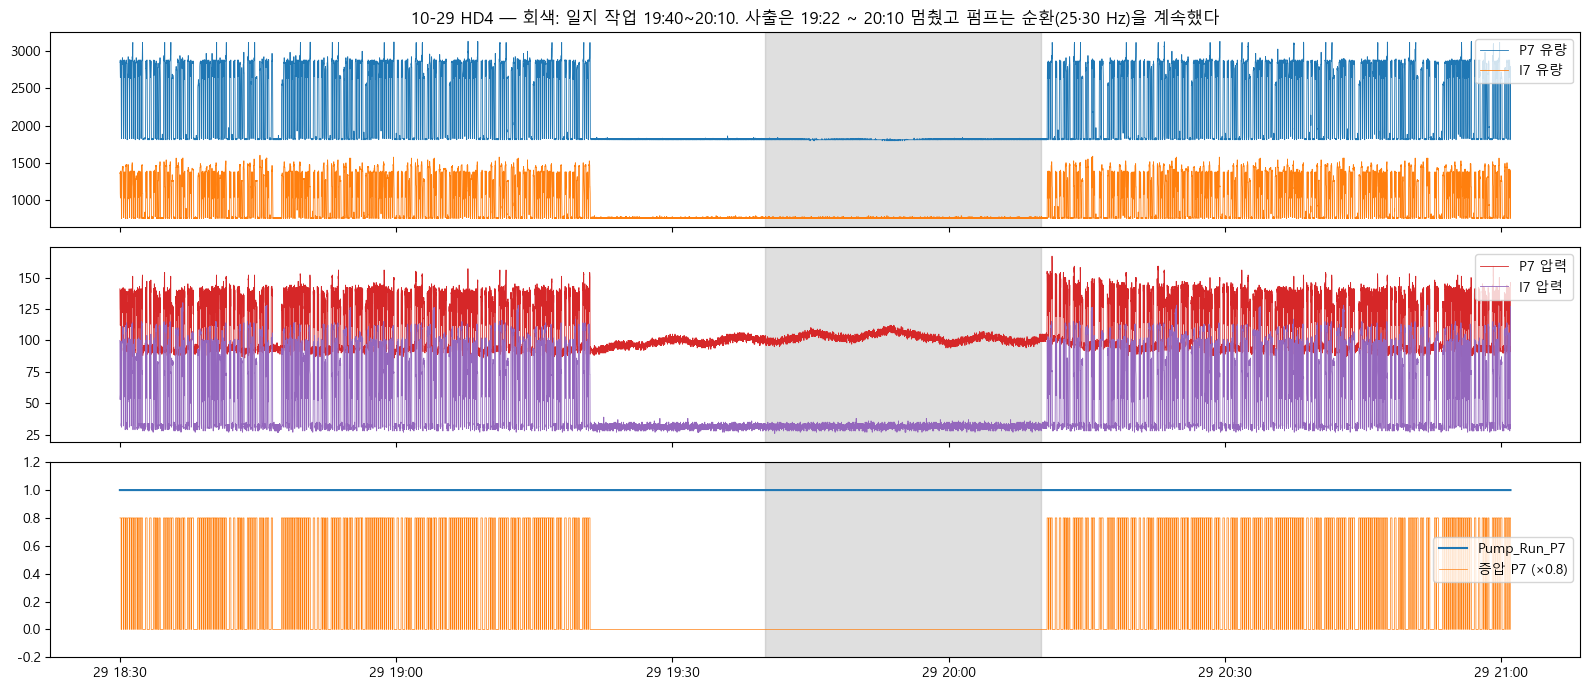

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(16, 7), sharex=True)
seg = R.loc["2026-10-29 18:30":"2026-10-29 21:00"]
axes[0].plot(seg.index, seg.FT_P7, lw=0.6, label="P7 유량"); axes[0].plot(seg.index, seg.FT_I7, lw=0.6, label="I7 유량"); axes[0].legend(loc="upper right")
axes[1].plot(seg.index, seg.PT_P7, lw=0.6, color="tab:red", label="P7 압력"); axes[1].plot(seg.index, seg.PT_I7, lw=0.6, color="tab:purple", label="I7 압력"); axes[1].legend(loc="upper right")
axes[2].step(seg.index, seg.Pump_Run_P7, where="post", label="Pump_Run_P7"); axes[2].step(seg.index, seg.BU_P7 * 0.8, where="post", lw=0.5, label="증압 P7 (×0.8)")
axes[2].legend(loc="center right"); axes[2].set_ylim(-0.2, 1.2)
for ax in axes:
    ax.axvspan(*EV, color="gray", alpha=0.25)
axes[0].set_title("10-29 HD4 — 회색: 일지 작업 19:40~20:10. 사출은 19:22 ~ 20:10 멈췄고 펌프는 순환(25·30 Hz)을 계속했다")
fig.tight_layout(); fig.savefig(FIGS / "P04_window.png", dpi=110, bbox_inches="tight")

## 4. 작업 전후 저항 — 어느 쪽 니플이었나

니플이 막혀 있었다면 바꾼 쪽 K가 내려가고, 새고 있었다면 올라간다. 순환(작업 중에도 돌았다)과 증압 둘 다 본다.
작업 구간은 사출이 멈춘 19:22부터로 잡는다.

In [8]:
T0 = pd.Timestamp("2026-10-29 19:22")
pd.concat({"P7 증압": h.before_after(R, "P7", T0, EV[1]), "P7 순환": h.before_after(R, "P7", T0, EV[1], buildup=0),
           "I7 증압": h.before_after(R, "I7", T0, EV[1]), "I7 순환": h.before_after(R, "I7", T0, EV[1], buildup=0)}).round(2)

n              FT             PT             K            
구간               전       후       전       후      전      후      전      후  변화%
      Hz                                                                   
P7 증압 3929   102.0   105.0  2848.0  2848.0  132.0  130.0  16.37  16.06 -1.9
P7 순환 2500  4569.0  5070.0  1826.0  1826.0   95.0   95.0  28.49  28.49  0.0
I7 증압 5711   102.0   105.0  1417.0  1417.0  103.0  103.0  51.30  51.30  0.0
I7 순환 3000  4570.0  5070.0   759.0   760.0   31.0   31.0  53.83  53.83  0.0

In [9]:
# 순환 중 작업 전·중·후 (작업 중에도 순환은 돌았다) — 10분 단위
c7, c1 = h.steady(R, "P7", 0, 2500), h.steady(R, "I7", 0, 3000)
pd.concat({"P7 순환 K": c7.K, "I7 순환 K": c1.K}, axis=1).loc["2026-10-29 18:00":"2026-10-29 21:30"].resample("10min").median().round(2).T

C:\Users\Home\AppData\Local\Temp\ipykernel_26480\2037859732.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  pd.concat({"P7 순환 K": c7.K, "I7 순환 K": c1.K}, axis=1).loc["2026-10-29 18:00":"2026-10-29 21:30"].resample("10min").median().round(2).T


Time,2026-10-29 18:00:00,2026-10-29 18:10:00,2026-10-29 18:20:00,2026-10-29 18:30:00,2026-10-29 18:40:00,2026-10-29 18:50:00,2026-10-29 19:00:00,2026-10-29 19:10:00,2026-10-29 19:20:00,2026-10-29 19:30:00,...,2026-10-29 20:00:00,2026-10-29 20:10:00,2026-10-29 20:20:00,2026-10-29 20:30:00,2026-10-29 20:40:00,2026-10-29 20:50:00,2026-10-29 21:00:00,2026-10-29 21:10:00,2026-10-29 21:20:00,2026-10-29 21:30:00
P7 순환 K,28.05,27.59,27.89,28.19,28.19,27.89,28.01,27.89,28.97,30.31,...,30.29,30.19,28.49,28.34,28.19,28.19,28.36,28.05,27.89,27.89
I7 순환 K,52.21,53.83,52.52,53.81,53.83,53.75,53.95,53.89,53.83,53.95,...,53.95,53.83,53.83,53.83,53.83,53.83,53.83,53.83,53.53,54.25


## 5. 일지에 없는 저항 계단 두 개

HD4 "헤드 토출 저항 증가"(W0066 P7 · W0067 I7, 10-26~)가 떠 있던 동안 실제로 움직인 것을 Hz 단계별로 본다.
- I7: 10-23 06:00~06:30 (생산 전 순환 중) 계단 상승
- P7: 10-28 오전 계단 하락
두 시각 모두 일지(공무반·기계실, 2라인)에 작업이 없다.

In [10]:
# 같은 Hz 단계끼리 이어 본 증압(자동 운전) 저항 K = PT/(FT/1000)² — 레시피가 바뀌어도 비교가 된다
kp, ki = h.hz_table(R, "P7"), h.hz_table(R, "I7")
pd.concat({"P7": kp, "I7": ki}, axis=1).loc["2026-10-15":"2026-11-12"].round(2)

P7                          I7                     
Hz           3650   3901   3929   3971   5057   5631   5711   6032
day                                                               
2026-10-15  19.53  17.87  17.68    NaN  43.33    NaN  42.80  42.88
2026-10-16  20.55  18.66  18.30  18.99  43.33    NaN  42.74  43.02
2026-10-17  20.83    NaN  19.17    NaN  43.33    NaN  42.80    NaN
2026-10-19  19.82    NaN    NaN  18.99  43.33    NaN    NaN    NaN
2026-10-20  19.97  18.70  17.62    NaN  43.30    NaN  42.80  43.02
2026-10-21  19.88    NaN  17.43    NaN  43.33    NaN  42.80    NaN
2026-10-22  20.03    NaN  17.56  17.51  43.33  42.83  42.80    NaN
2026-10-23  19.93  18.37  17.57  18.21  52.24  51.67  51.80  51.66
2026-10-24  19.97    NaN  17.56  17.57  52.24  51.61  51.35    NaN
2026-10-26  20.11    NaN  17.54  17.43  52.24  51.61  51.35    NaN
2026-10-27  19.96    NaN  17.62  17.54  52.11  51.61  51.35    NaN
2026-10-28  18.58    NaN  16.19  16.48  51.80  51.61  51.30    NaN
2026-10-29  18.60    NaN  16.19    NaN  51.62    NaN  51.30    NaN
2026-10-30  18.38  16.95  16.16    NaN  51.98    NaN  51.30  51.66
2026-10-31  18.80    NaN  16.13    NaN  52.61    NaN  51.30    NaN
2026-11-02  18.95    NaN  16.56  16.50  51.62  51.61  51.30    NaN
2026-11-03  19.17    NaN  16.64  16.62  52.61  51.53  51.30    NaN
2026-11-04    NaN    NaN  16.81  16.50    NaN  51.61  51.67    NaN
2026-11-05    NaN    NaN  16.47  16.48    NaN  51.61  51.35    NaN
2026-11-06    NaN    NaN  16.40    NaN    NaN    NaN  51.62    NaN
2026-11-09    NaN  17.34  16.44    NaN    NaN    NaN  51.30  51.66
2026-11-10    NaN  17.37  16.60  17.43    NaN    NaN  51.30  51.66
2026-11-11    NaN    NaN  16.40  16.41    NaN  51.61  51.32    NaN
2026-11-12    NaN    NaN  16.40  16.47    NaN  51.61  51.30    NaN

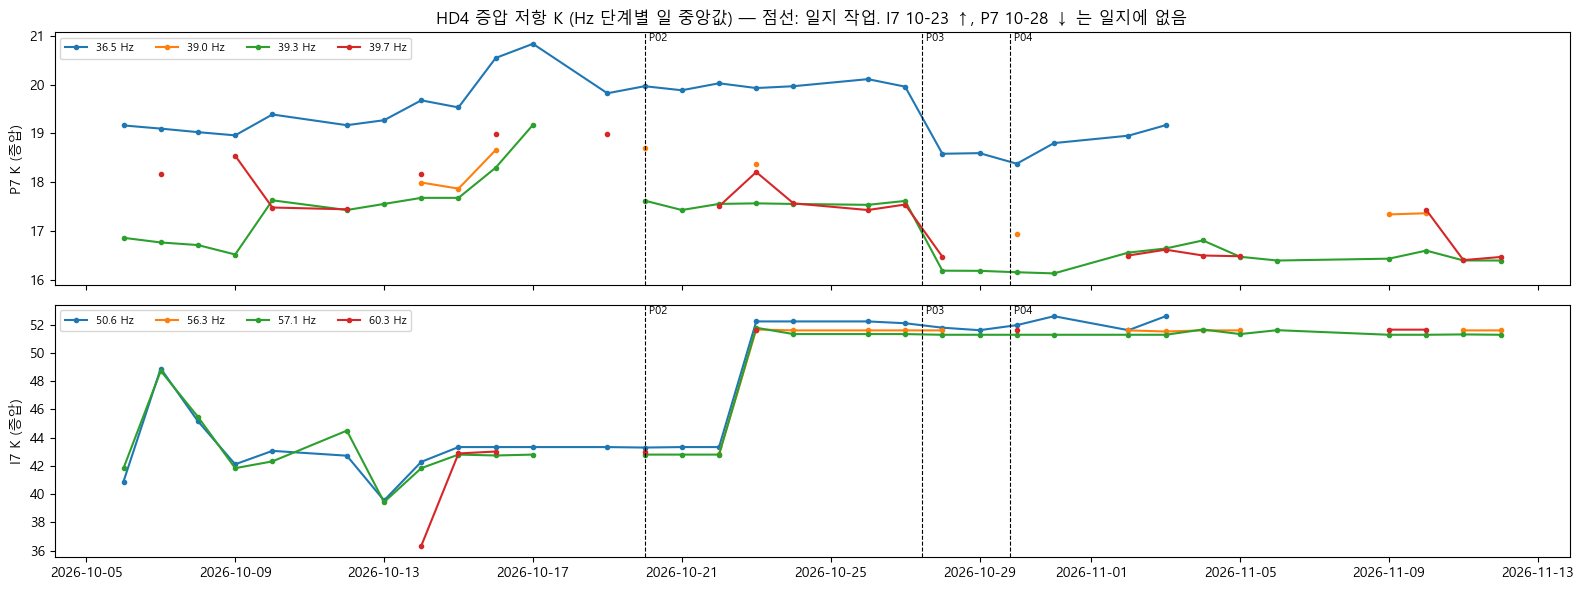

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
for ax, (p, t) in zip(axes, [("P7", kp), ("I7", ki)]):
    for hz in t.columns:
        ax.plot(t.index, t[hz], "o-", ms=3, label=f"{hz / 100:.1f} Hz")
    ax.set_ylabel(f"{p} K (증압)"); ax.legend(loc="upper left", ncol=4, fontsize=8)
    h.mark(ax, label=True)
axes[0].set_title("HD4 증압 저항 K (Hz 단계별 일 중앙값) — 점선: 일지 작업. I7 10-23 ↑, P7 10-28 ↓ 는 일지에 없음")
fig.tight_layout(); fig.savefig(FIGS / "P04_K.png", dpi=110, bbox_inches="tight")

In [12]:
# 계단 시각 — 순환 K 30분 단위
pd.concat({"I7 순환 K (10-22~23)": c1.K.loc["2026-10-22 20:00":"2026-10-23 10:00"].resample("30min").median(),
           "P7 순환 K (10-27~28)": c7.K.loc["2026-10-27 20:00":"2026-10-28 16:00"].resample("30min").median()}, axis=1).dropna(how="all").round(2)

,I7 순환 K (10-22~23),P7 순환 K (10-27~28)
Time,,
2026-10-22 20:00:00,43.74,NaN
2026-10-22 20:30:00,43.74,NaN
2026-10-22 21:00:00,43.74,NaN
2026-10-22 21:30:00,43.74,NaN
2026-10-22 22:00:00,43.74,NaN
2026-10-22 22:30:00,43.74,NaN
2026-10-22 23:00:00,43.74,NaN
2026-10-22 23:30:00,43.74,NaN
2026-10-23 00:00:00,43.74,NaN


In [13]:
# 계단 크기 — 계단 앞뒤 3 가동일, 같은 Hz 단계
def step(t, p, d0, d1, d2, d3):
    a, b = t.loc[d0:d1].median(), t.loc[d2:d3].median()
    return pd.DataFrame({"전": a, "후": b, "변화%": (b / a - 1) * 100}).dropna()
pd.concat({"I7 10-23": step(ki, "I7", "2026-10-20", "2026-10-22", "2026-10-23", "2026-10-26"),
           "P7 10-28": step(kp, "P7", "2026-10-24", "2026-10-27", "2026-10-28", "2026-10-31")}).round(2)

전      후    변화%
         Hz                       
I7 10-23 5057  43.33  52.24  20.56
         5631  42.83  51.61  20.49
         5711  42.80  51.35  19.97
         6032  43.02  51.66  20.09
P7 10-28 3650  19.97  18.59  -6.90
         3929  17.56  16.17  -7.88
         3971  17.54  16.48  -6.09

## 6. 재생 — 일별 피처 추세, 그때 모델 상태

In [14]:
# 운영 펌프 모델 재생 (P7·I7, 10-06 ~ 11-12). 처음 한 번 약 1시간 반 → cache/replay/hd4_P7I7_1006_1112.pkl
C = h.replay_cycles()
dP7, dI7 = h.daily_features(C, "P7"), h.daily_features(C, "I7")
pd.concat({"P7": dP7, "I7": dI7}, axis=1).loc["2026-10-20":"2026-11-12"].round(3)

P7                                                                      ...     I7                                                                  
               n  알림창비율     PT     P0  FT_SV pump_resid r_phys    z_r   z_P0 z_resid  ...  알림창비율    PT    P0  FT_SV pump_resid r_phys    z_r   z_P0 z_resid  score
day                                                                                   ...                                                                         
2026-10-20  3085  0.364  150.0   98.0  1.001     -0.535  1.071  0.666  0.333  -0.170  ...  0.976  84.5  26.0  1.009      0.051  0.946 -1.142 -0.450  -0.044  3.551
2026-10-21  3020  0.468  148.0   98.0  1.005     -0.019  1.064  0.621  0.333  -0.002  ...  0.974  84.5  26.0  1.013      0.546  0.951 -1.041 -0.450   0.028  3.029
2026-10-22  2790  0.527  149.0   98.0  1.001     -0.534  1.067  0.579  0.333  -0.169  ...  0.970  84.0  26.0  1.009      0.066  0.946 -1.168 -0.450  -0.043  4.091
2026-10-23  3010  0.332  149.0   97.0  1.002     -0.487  1.067  0.538  0.222  -0.132  ...  0.977  99.5  31.0  0.998      0.561  1.110  2.311  0.674   0.035  0.992
2026-10-24  3075  0.261  150.5   98.0  1.003     -0.280  1.067  0.597  0.333  -0.081  ...  0.979  99.0  31.0  1.000      0.658  1.112  2.328  0.674   0.046  0.879
2026-10-26  3251  0.448  149.0   98.0  1.001     -0.534  1.067  0.544  0.333  -0.161  ...  0.978  99.0  31.0  0.998      0.550  1.109  2.280  0.674   0.037  0.972
2026-10-27  3226  0.233  149.0   98.0  1.002     -0.534  1.064  0.624  0.333  -0.169  ...  0.978  99.0  31.0  0.998      0.545  1.107  2.228  0.674   0.027  0.896
2026-10-28  3270  0.069  139.0   93.0  1.005     -0.014  0.989 -0.272 -0.222   0.001  ...  0.980  99.0  31.0  0.998      0.545  1.105  2.187  0.674   0.027  0.800
2026-10-29  3163  0.026  139.0   93.0  1.005     -0.014  0.990 -0.240 -0.222   0.001  ...  0.976  99.0  31.0  0.998      0.484  1.104  2.159  0.674   0.018  0.810
2026-10-30  3312  0.066  138.0   92.0  1.005     -0.014  0.983 -0.304 -0.300   0.001  ...  0.977  99.0  31.0  0.997      0.489  1.103  2.139  0.674   0.018  0.754
2026-10-31  3256  0.006  139.0   92.0  1.005     -0.012  0.983 -0.289 -0.300   0.002  ...  0.980  99.0  31.0  0.998      0.484  1.103  2.125  0.674   0.016  0.664
2026-11-02  3477  0.071  141.0   94.0  1.005     -0.016  1.004 -0.099 -0.100   0.000  ...  0.982  99.0  31.0  0.998      0.515  1.105  2.169  0.674   0.022  0.800
2026-11-03  2644  0.001  143.0   96.0  1.005     -0.014  1.011 -0.008  0.100   0.001  ...  0.956  99.0  31.0  0.998      0.558  1.106  2.204  0.674   0.029  0.677
2026-11-04  2919  0.000  142.0   95.0  1.005     -0.014  1.007 -0.049  0.000   0.001  ...  0.964  99.0  31.0  0.996      0.506  1.106  2.218  0.674   0.022  0.788
2026-11-05  3632  0.031  141.0   94.0  1.005     -0.012  0.998 -0.140 -0.100   0.002  ...  0.977  99.0  31.0  0.996      0.505  1.105  2.185  0.674   0.022  0.733
2026-11-06  3458  0.013  140.5   94.0  1.006     -0.004  0.997 -0.165 -0.111   0.058  ...  0.977  99.0  31.0  0.999      0.555  1.108  2.270  0.674   0.032  0.828
2026-11-07     3  0.000  154.0  104.0  1.003     -0.170  1.089  0.393  1.000   0.075  ...  0.000  98.0  31.0  0.999      0.617  1.117  2.493  0.674   0.132  1.328
2026-11-09  3577  0.006  141.0   95.0  1.005     -0.012  1.001 -0.102  0.000   0.001  ...  0.973  98.5  31.0  0.997      0.526  1.105  2.175  0.674   0.026  0.715
2026-11-10  3420  0.000  141.0   94.0  1.005     -0.013  0.998 -0.141 -0.100   0.001  ...  0.973  99.0  31.0  0.997      0.512  1.103  2.135  0.674   0.021  0.721
2026-11-11  3009  0.002  140.0   94.0  1.005     -0.014  0.996 -0.177 -0.111   0.001  ...  0.968  98.5  31.0  0.998      0.504  1.104  2.154  0.674   0.018  0.776
2026-11-12  3413  0.029  140.0   94.0  1.005     -0.013  0.996 -0.184 -0.111   0.001  ...  0.979  98.5  31.0  0.997      0.452  1.103  2.135  0.674   0.011  0.718

[21 rows x 22 columns]

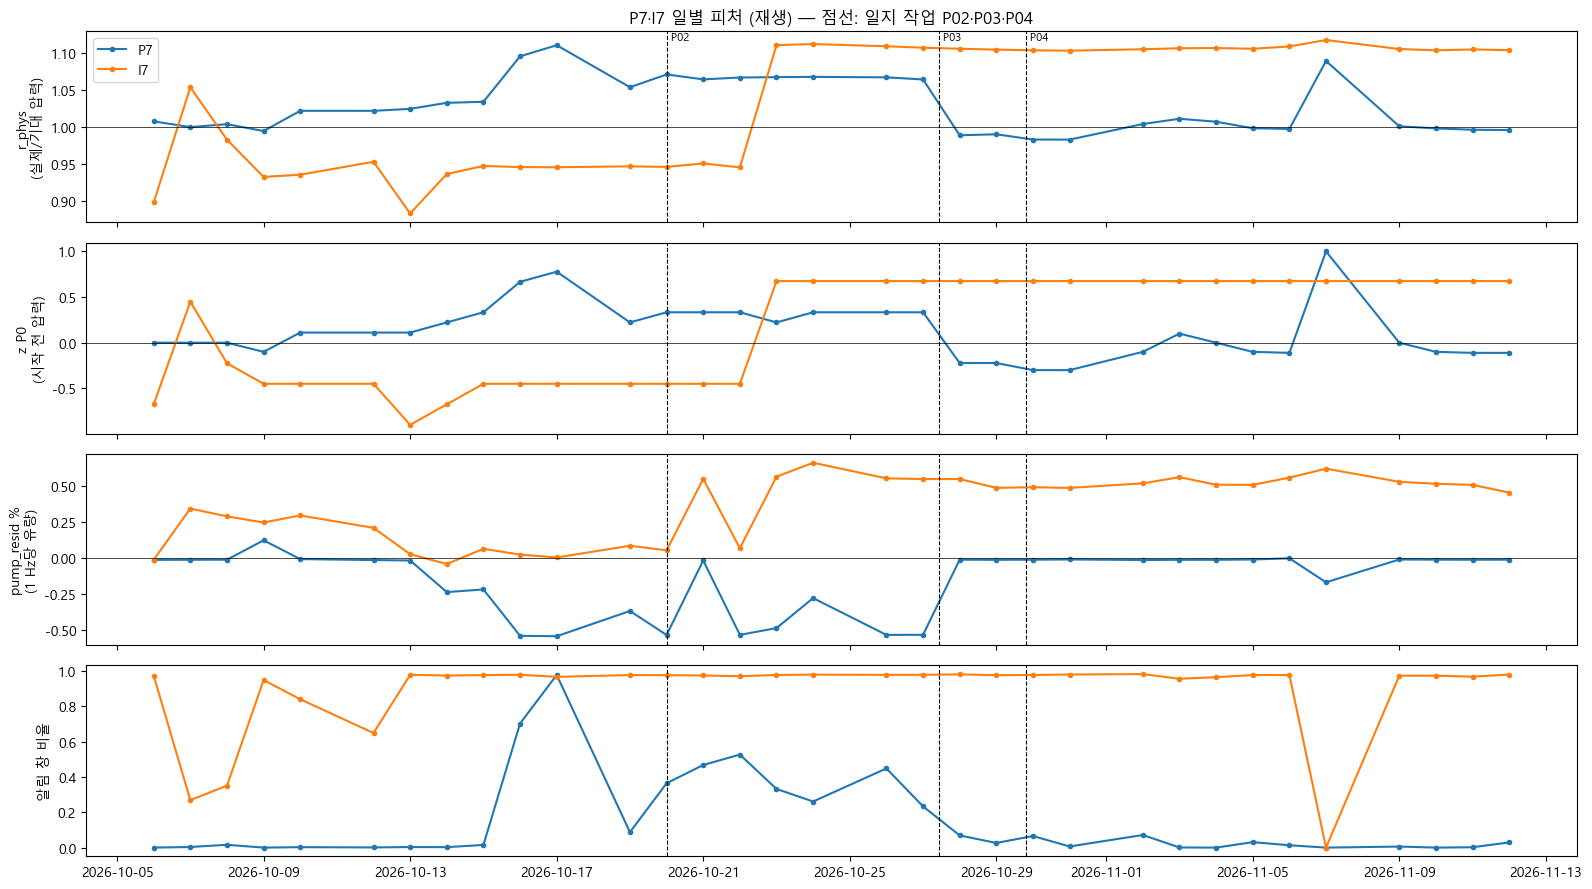

In [15]:
fig, axes = plt.subplots(4, 1, figsize=(16, 9), sharex=True)
for p, d, c in [("P7", dP7, "tab:blue"), ("I7", dI7, "tab:orange")]:
    axes[0].plot(d.index, d.r_phys, "o-", ms=3, color=c, label=p)
    axes[1].plot(d.index, d.z_P0, "o-", ms=3, color=c, label=p)
    axes[2].plot(d.index, d.pump_resid, "o-", ms=3, color=c, label=p)
    axes[3].plot(d.index, d["알림창비율"], "o-", ms=3, color=c, label=p)
axes[0].axhline(1, color="k", lw=0.5); axes[0].set_ylabel("r_phys\n(실제/기대 압력)")
axes[1].axhline(0, color="k", lw=0.5); axes[1].set_ylabel("z P0\n(시작 전 압력)")
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_ylabel("pump_resid %\n(1 Hz당 유량)")
axes[3].set_ylabel("알림 창 비율"); axes[0].legend(loc="upper left")
for ax in axes:
    h.mark(ax, label=ax is axes[0])
axes[0].set_title("P7·I7 일별 피처 (재생) — 점선: 일지 작업 P02·P03·P04")
fig.tight_layout(); fig.savefig(FIGS / "P04_trend.png", dpi=110, bbox_inches="tight")

In [16]:
# 작업 전후 그리고 두 계단 전후, 모델 창 상태 (자동 운전 사이클, 2시간 단위)
x = C[C.pump.isin(["P7", "I7"]) & (C["mode"] == "자동 운전") & C.t.between("2026-10-28 06:00", "2026-10-30 12:00")]
x.groupby(["pump", x.t.dt.floor("2h")]).agg(n=("t", "size"), score=("score", "median"), z_r=("zn_r_phys", "median"), z_P0=("zn_P0", "median"),
    level=("pump_level", lambda s: s.value_counts().index[0])).unstack("pump").round(2)

n      score         z_r        z_P0       level    
pump                  I7   P7    I7    P7    I7    P7    I7    P7    I7  P7
t                                                                          
2026-10-28 06:00:00  215  215  0.77  0.45  2.32  0.80  0.67  0.50    알림  주의
2026-10-28 08:00:00  362  362  0.87  0.29  2.24  0.33  0.67  0.22    알림  알림
2026-10-28 10:00:00  227  227  0.85  0.16  2.20 -0.17  0.67 -0.11    알림  정상
2026-10-28 12:00:00  422  422  0.77  0.17  2.16 -0.29  0.67 -0.22    알림  정상
2026-10-28 14:00:00  437  437  0.79  0.18  2.15 -0.33  0.67 -0.33    알림  정상
2026-10-28 16:00:00  428  428  0.76  0.18  2.17 -0.33  0.67 -0.30    알림  정상
2026-10-28 18:00:00  324  324  0.79  0.21  2.22 -0.36  0.67 -0.33    알림  정상
2026-10-28 20:00:00  431  431  0.85  0.18  2.21 -0.29  0.67 -0.22    알림  정상
2026-10-28 22:00:00  424  424  0.76  0.17  2.16 -0.33  0.67 -0.33    알림  정상
2026-10-29 06:00:00  252  252  0.89  0.13  2.26 -0.11  0.67  0.00    알림  정상
2026-10-29 08:00:00  396  396  0.79  0.18  2.18 -0.21  0.67 -0.20    알림  정상
2026-10-29 10:00:00  255  255  0.82  0.18  2.16 -0.19  0.67 -0.20    알림  정상
2026-10-29 12:00:00  396  396  0.85  0.17  2.15 -0.27  0.67 -0.22    알림  정상
2026-10-29 14:00:00  410  410  0.79  0.17  2.17 -0.27  0.67 -0.22    알림  정상
2026-10-29 16:00:00  385  385  0.83  0.16  2.15 -0.21  0.67 -0.22    알림  정상
2026-10-29 18:00:00  302  302  0.84  0.15  2.14 -0.29  0.67 -0.22    알림  정상
2026-10-29 20:00:00  395  395  0.76  0.17  2.15 -0.25  0.67 -0.22    알림  정상
2026-10-29 22:00:00  372  372  0.78  0.19  2.12 -0.24  0.67 -0.22    알림  정상
2026-10-30 06:00:00  237  237  0.78  0.19  2.21 -0.09  0.67 -0.10    알림  정상
2026-10-30 08:00:00  387  387  0.86  0.18  2.14 -0.19  0.67 -0.11    알림  정상
2026-10-30 10:00:00  244  244  0.81  0.16  2.18 -0.18  0.67 -0.20    알림  정상